<a href="https://colab.research.google.com/github/vishwa24816/Volatility-Drag/blob/main/Volatility_Drag.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Setup, data download, and summary statistics
# Purpose: pull ~12 years of adjusted prices for SPY (low vol) and TQQQ (3x leveraged, high vol),
# compute simple and log returns, and measure the arithmetic-vs-geometric gap (volatility drag).
# Required packages: yfinance, numpy, pandas, matplotlib, scipy

# !pip install yfinance numpy pandas matplotlib scipy   # run once if needed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from scipy import stats

TICKERS = ["SPY", "TQQQ"]

# Download adjusted prices (auto_adjust=True folds dividends/splits into Close)
raw = yf.download(TICKERS, start="2014-01-01", auto_adjust=True, progress=False)
prices_all = raw["Close"][TICKERS]

# Drop missing rows and report how many were removed
n_before = len(prices_all)
prices = prices_all.dropna()
print(f"Rows removed for missing data: {n_before - len(prices)} of {n_before}")
print(f"Sample: {prices.index[0].date()} to {prices.index[-1].date()}")

# Daily simple and log returns
simple = prices.pct_change().dropna()
logr = np.log(prices / prices.shift(1)).dropna()

# Summary table (annualized, 252 trading days)
rows = {}
for t in TICKERS:
    arith = simple[t].mean() * 252
    vol = simple[t].std() * np.sqrt(252)
    geo = logr[t].mean() * 252
    rows[t] = {
        "Arithmetic mean (ann.)": arith,
        "Volatility (ann.)": vol,
        "Geometric growth (ann.)": geo,
        "Realized drag (arith - geo)": arith - geo,
    }
summary = pd.DataFrame(rows).T
summary.style.format("{:.2%}")

Rows removed for missing data: 0 of 3226
Sample: 2014-01-02 to 2026-10-29


,Arithmetic mean (ann.),Volatility (ann.),Geometric growth (ann.),Realized drag (arith - geo)
SPY,14.35%,17.08%,12.89%,1.47%
TQQQ,51.96%,63.25%,31.72%,20.24%


Start:          $100.00
After +50%:     $150.00
After -50%:     $75.00
Net change:     -25.00%


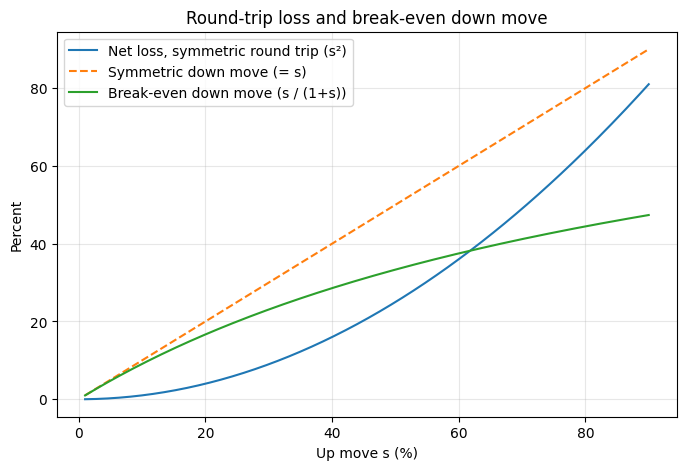

Break-even down move for +50%: 33.33%


In [2]:
# The two-step example and the general round-trip
# A +50% gain followed by a -50% loss does not return to the start.
# For a symmetric swing of size s, the round trip is (1+s)(1-s) = 1 - s^2, so the net loss is s^2.
# The break-even down move after an up move of s is d* = s/(1+s), which is smaller than s.

# Worked example: $100 -> +50% -> -50%
balance = 100.0
after_up = balance * 1.50
after_down = after_up * 0.50
net = after_down / balance - 1
print(f"Start:          ${balance:,.2f}")
print(f"After +50%:     ${after_up:,.2f}")
print(f"After -50%:     ${after_down:,.2f}")
print(f"Net change:     {net:.2%}")

# Generalize over swing sizes s = 1% to 90%
s = np.linspace(0.01, 0.90, 200)
loss_symmetric = s**2                  # net loss from a symmetric round trip
d_breakeven = s / (1 + s)              # down move that exactly recovers the gain

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(s * 100, loss_symmetric * 100, label="Net loss, symmetric round trip (s²)")
ax.plot(s * 100, s * 100, "--", label="Symmetric down move (= s)")
ax.plot(s * 100, d_breakeven * 100, label="Break-even down move (s / (1+s))")
ax.set_xlabel("Up move s (%)")
ax.set_ylabel("Percent")
ax.set_title("Round-trip loss and break-even down move")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# Check the +50% case: break-even down move should be 1/3
print(f"Break-even down move for +50%: {0.5/1.5:.2%}")

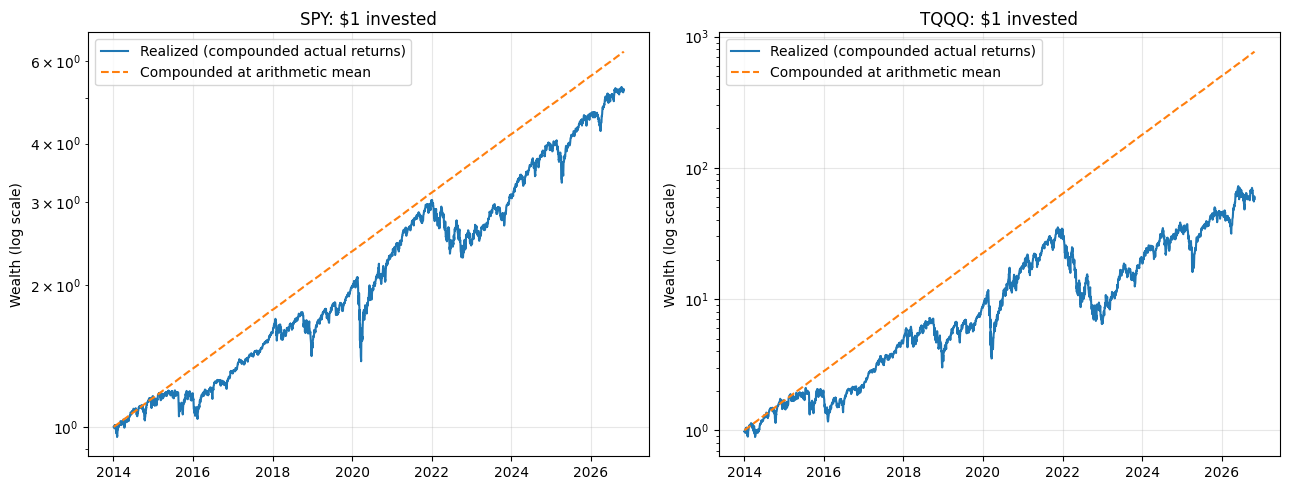

,Predicted drag (½σ²),Realized drag,Predicted vs realized (% diff)
Ticker,,,
SPY,1.46%,1.47%,-0.46%
TQQQ,20.00%,20.24%,-1.21%


In [3]:
# Empirical drag from historical returns
# Compare the realized wealth path with a path compounded at the arithmetic mean.
# The gap is the drag: compounding a volatile series at its average rate overstates the result.
# The rule of thumb predicts annual drag ≈ ½σ². We compare it with the realized drag from Section 1.

n = len(simple)
t_idx = np.arange(1, n + 1)

wealth_real = (1 + simple).cumprod()
wealth_arith = pd.DataFrame(
    {t: (1 + simple[t].mean()) ** t_idx for t in TICKERS},
    index=simple.index,
)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=False)
for ax, t in zip(axes, TICKERS):
    ax.plot(wealth_real.index, wealth_real[t], label="Realized (compounded actual returns)")
    ax.plot(wealth_arith.index, wealth_arith[t], "--", label="Compounded at arithmetic mean")
    ax.set_yscale("log")
    ax.set_title(f"{t}: $1 invested")
    ax.set_ylabel("Wealth (log scale)")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Compare predicted drag (½σ²) with realized drag from Section 1
rows = []
for t in TICKERS:
    vol = simple[t].std() * np.sqrt(252)
    predicted = 0.5 * vol**2
    realized = summary.loc[t, "Realized drag (arith - geo)"]
    pct_diff = (predicted - realized) / realized
    rows.append({
        "Ticker": t,
        "Predicted drag (½σ²)": predicted,
        "Realized drag": realized,
        "Predicted vs realized (% diff)": pct_diff,
    })
drag_table = pd.DataFrame(rows).set_index("Ticker")
drag_table.style.format("{:.2%}")

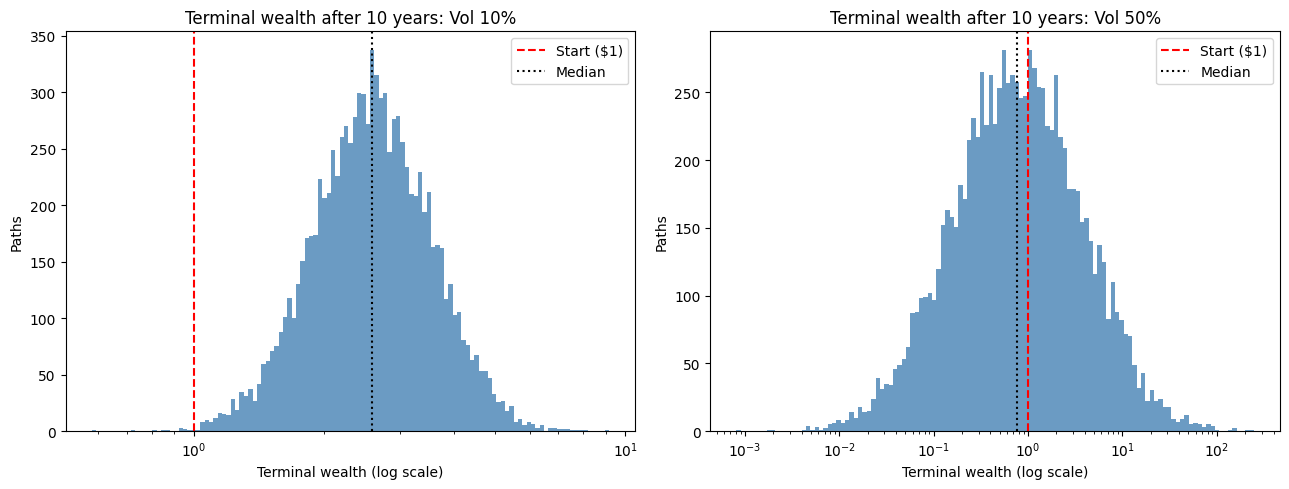

In [4]:
# Monte Carlo under geometric Brownian motion
# Two synthetic assets, both with a 10% arithmetic annual mean, and volatilities of 10% and 50%.
# Daily log returns are X ~ N(μ_log, σ_d²), with μ_log chosen so E[exp(X)] = 1 + 0.10/252.
# Simulated paths are generated as one vectorized array, with no Python loops over paths.

rng = np.random.default_rng(42)

N_PATHS = 10_000
YEARS = 10
STEPS = 252 * YEARS            # 2,520 daily steps
TARGET_ARITH_ANN = 0.10
TARGET_ARITH_DAILY = TARGET_ARITH_ANN / 252

results = {}
terminal_wealth = {}

for label, sigma_ann in [("Vol 10%", 0.10), ("Vol 50%", 0.50)]:
    sigma_d = sigma_ann / np.sqrt(252)
    # Daily drift so that E[simple return] = 0.10/252 under lognormal returns
    mu_log = np.log(1 + TARGET_ARITH_DAILY) - 0.5 * sigma_d**2

    # Shape (paths, steps); float32 keeps memory near 100 MB per array
    Z = rng.standard_normal((N_PATHS, STEPS), dtype=np.float32)
    X = mu_log + sigma_d * Z                # daily log returns
    R = np.expm1(X)                         # daily simple returns

    avg_ann_arith = R.mean(axis=1) * 252    # each path's average annualized return
    terminal_logw = X.sum(axis=1)           # terminal log wealth per path
    growth = terminal_logw / YEARS          # realized growth rate per path

    results[label] = {
        "Mean of simulated arithmetic returns": avg_ann_arith.mean(),
        "Median realized growth rate": np.median(growth),
        "Mean realized growth rate": growth.mean(),
        "Fraction of paths ending below start": (terminal_logw < 0).mean(),
        "Predicted drag (½σ²)": 0.5 * sigma_ann**2,
    }
    terminal_wealth[label] = np.exp(terminal_logw)

    del Z, X, R  # free memory before the next asset

summary_mc = pd.DataFrame(results).T
summary_mc.style.format("{:.2%}")

# Histograms of terminal wealth on a log scale
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (label, w) in zip(axes, terminal_wealth.items()):
    ax.hist(w, bins=np.logspace(np.log10(w.min()), np.log10(w.max()), 120), color="steelblue", alpha=0.8)
    ax.set_xscale("log")
    ax.axvline(1.0, color="red", ls="--", label="Start ($1)")
    ax.axvline(np.median(w), color="black", ls=":", label="Median")
    ax.set_title(f"Terminal wealth after 10 years: {label}")
    ax.set_xlabel("Terminal wealth (log scale)")
    ax.set_ylabel("Paths")
    ax.legend()
plt.tight_layout()
plt.show()

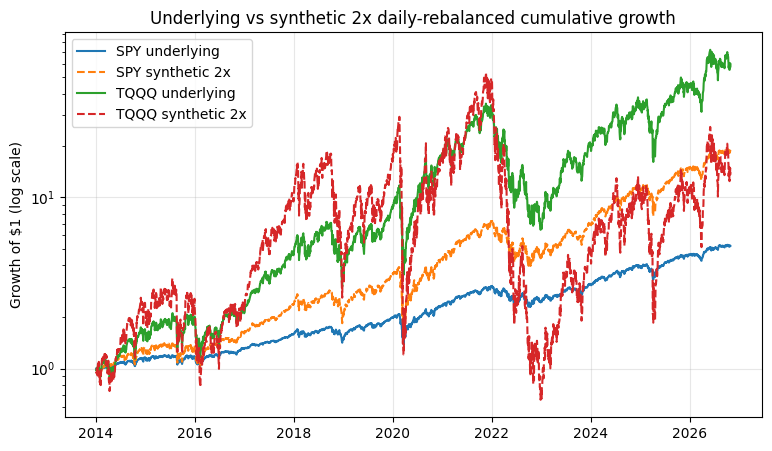

In [5]:
# Leveraged fund check and findings
# Build a synthetic 2x daily-rebalanced position from the Section 1 returns: r_lev = 2 * r_t.
# Compounding 2x daily returns is not the same as doubling the underlying's cumulative return.
# The gap comes from volatility drag and should widen as volatility rises.
#
# Limitations: the results depend on this sample period; GBM assumes lognormal, i.i.d. returns;
# fees, financing costs, and taxes are ignored.

rows = []
for t in TICKERS:
    r = simple[t]
    cum_und = (1 + r).cumprod().iloc[-1] - 1
    cum_2x_linear = 2 * cum_und                    # 2 x underlying's cumulative return
    cum_2x_compound = (1 + 2 * r).cumprod().iloc[-1] - 1   # daily-rebalanced 2x
    rows.append({
        "Ticker": t,
        "Ann. volatility": r.std() * np.sqrt(252),
        "Underlying cum. return": cum_und,
        "2x of underlying (linear)": cum_2x_linear,
        "Synthetic 2x (compounded)": cum_2x_compound,
        "Gap (linear - compounded)": cum_2x_linear - cum_2x_compound,
    })
lev_table = pd.DataFrame(rows).set_index("Ticker")
lev_table.style.format("{:.2%}")

# Plot cumulative paths for both tickers
fig, ax = plt.subplots(figsize=(9, 5))
for t in TICKERS:
    r = simple[t]
    ax.plot(r.index, (1 + r).cumprod(), label=f"{t} underlying")
    ax.plot(r.index, (1 + 2 * r).cumprod(), "--", label=f"{t} synthetic 2x")
ax.set_yscale("log")
ax.set_title("Underlying vs synthetic 2x daily-rebalanced cumulative growth")
ax.set_ylabel("Growth of $1 (log scale)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()